# 08. Classification dataset profile and collection handoff

This notebook documents the external development and test parcels used in the saved classification experiment and the reference evidence available in Paoay, Atok, Benguet, Philippines. It begins with why each source was included, traces the original crop labels into the experiment, and ends with collection status for the next preprocessing run.

## Settings

The paths are relative to the repository. The profile uses the November 19 parcel audits and their corresponding feature export. Change these three inputs together when reporting a different experiment. The Paoay bundle identifies the reviewed study boundary and reference areas. The cohort is matched so the two window recipes can be compared on the same locations.

In [1]:
# Select the saved experiment and the reviewed Paoay boundary bundle.
development_audit = "pipeline_outputs/development_error_review_2026-11-19/parcel_diagnostics.json"
test_audit = "pipeline_outputs/test_audit_2026-11-19/parcel_audit.json"
feature_export = "pipeline_outputs/preprocessing/external_xxu0iz4o/features"
paoay_bundle = "data/pipeline_work/paoay/references/bundles/eff4797788de4f7c3d98"

In [2]:
from pathlib import Path
import json
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))

from crop_pipeline.collection_summary import write_summary
from crop_pipeline.notebook_display import show_table

show_table([
    {"Evidence": "Collection and test parcel audits", "Snapshot": Path(test_audit).parent.name},
    {"Evidence": "Development parcel audit", "Snapshot": Path(development_audit).parent.name},
    {"Evidence": "Feature export", "Snapshot": Path(feature_export).parent.name},
    {"Evidence": "Paoay reference bundle", "Snapshot": Path(paoay_bundle).name},
], title="Saved inputs for this profile")

Evidence,Snapshot
Collection and test parcel audits,test_audit_2026-11-19
Development parcel audit,development_error_review_2026-11-19
Feature export,external_xxu0iz4o
Paoay reference bundle,eff4797788de4f7c3d98


## 1. Why these sources were selected

Paoay and neighbouring Cattubo are documented production areas for carrot, cabbage and potato. The external development sources provide traceable crop labels and parcel boundaries or masks. Independent campaigns then let us examine transfer across locations and label sources. See the [Atok farming study](https://pidswebs.pids.gov.ph/CDN/document/pidsrp2303.pdf) and the [JECAM site descriptions](https://essd.copernicus.org/articles/13/5951/2021/index.html).

**Table 1. Dataset register and selection rationale**

| Source | Role and selected geography | Crop contribution and reason for inclusion |
|---|---|---|
| Sen4AgriNet | Development · Spain and France · 2019–2020 | Carrot and potato under one labelling system across two countries. Annual crop labels leave the exact crop cycle uncertain. |
| FranceCrops | Development · France · 2022 | Explicit cabbage and table-potato labels joined to parcel geometry. Supplies all matched development cabbage. |
| EuroCrops | Development · Netherlands · 2021 | An additional source of declared carrot parcels. The Dutch cabbage test campaign was retired after insufficient clear-pixel support was reported. |
| CropHarvest JECAM | Primary external test · Madagascar and Senegal · 2019 and 2021 | Independently collected observations. Madagascar offers a tropical highland small-field comparison. Senegal adds a cabbage campaign. |
| California DWR | Supplemental test · California · 2023 | Single-crop carrot polygons test recognition in a distinct production setting. |
| Denmark Marker | Supplemental test · Denmark · 2023 | Declared white and red cabbage provides a cabbage check outside the development source. |
| CropHarvest non-JECAM | Supplemental tests · Île-de-France, Martinique and Réunion · 2019 | Adds cabbage, carrot and potato checks, including different potato use types. Some dates are annual placeholders. |
| Paoay references | Local application context · Atok, Benguet | Boundary and calendar notes guide imagery assessment and field planning. The crop occupying a particular field during the historical imagery window remains unverified. |

## 2. How source labels become project crop classes

Retain the original label in the reference record. This makes it possible to inspect whether differences between campaigns reflect different meanings of a broad crop class.

**Table 2. Crop-label crosswalk**

| Project class | Original codes or labels in the saved experiment |
|---|---|
| Carrot | Sen4AgriNet **231** · EuroCrops **2717, 2783, 2785** · JECAM **carrot** · California DWR **T6** · non-JECAM **carotte** |
| Cabbage | FranceCrops **CHU** · JECAM **cabbage** · Denmark Marker **408/418** (campaign code set) · non-JECAM **chou** |
| Potato | Sen4AgriNet **510** · FranceCrops **PTC** (table potato) · JECAM **potato** · non-JECAM **pomme de terre de consommation** and **pomme de terre féculière** |

The Dutch cabbage campaign is excluded from this crosswalk. Local decisions still include whether Chinese cabbage or pechay falls outside the target cabbage definition and how local potato names correspond to the external use types. [Dataset register and crosswalk](../../docs/classification_dataset_register.md)

## 3. Which parcels entered the experiment

Count each parcel group once per split. The saved geographic out-of-fold audit covers the training parcels and the locked validation audit covers the validation parcels. Test field counts come from the saved parcel audit. The resulting crop totals are checked against the matched feature export before the detailed profile is displayed.

Split,Source,Site,Carrot,Cabbage,Potato,Total
Train,EuroCrops,Netherlands,47,0,0,47
Train,FranceCrops,France,0,50,11,61
Train,Sen4AgriNet,France,7,0,12,19
Train,Sen4AgriNet,Spain,18,0,54,72
Validation,EuroCrops,Netherlands,11,0,0,11
Validation,FranceCrops,France,0,13,8,21
Validation,Sen4AgriNet,France,2,0,6,8
Validation,Sen4AgriNet,Spain,4,0,25,29
Test,California DWR,California,62,0,0,62
Test,Denmark Marker,Denmark,0,15,0,15


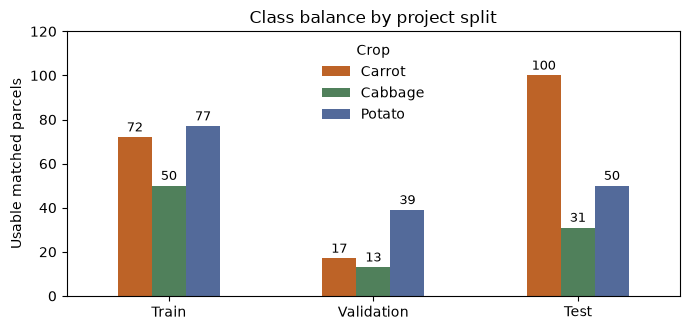

Cohort,Partition,Cabbage,Carrot,Potato
aligned_full,Reserved test,37,107,55
aligned_full,Training,66,107,87
aligned_full,Validation,21,31,43
fixed_full,Reserved test,67,156,145
fixed_full,Training,449,269,358
fixed_full,Validation,129,94,147


In [3]:
crops = ["Carrot", "Cabbage", "Potato"]
splits = {"geographic_cv": "Train", "locked_validation": "Validation"}
source_names = {
    "sen4agrinet": "Sen4AgriNet", "francecrops": "FranceCrops", "eurocrops": "EuroCrops",
    "jecam": "JECAM",
    "california_dwr_carrot_2023_v1": "California DWR",
    "denmark_marker_cabbage_2023_v1": "Denmark Marker",
    "non_jecam_cabbage_supplement_v1": "Non-JECAM cabbage",
    "non_jecam_carrot_potato_supplement_v1": "Non-JECAM carrot/potato",
}
site_names = {
    "ES": "Spain", "FR": "France", "NL": "Netherlands", "US": "California", "DK": "Denmark",
    "ile-de-france": "Île-de-France", "martinique-france": "Martinique", "reunion-france": "Réunion",
}
input_paths = [root / development_audit, root / test_audit, root / feature_export / "usable_samples.csv"]
profile_available = False
if all(path.is_file() for path in input_paths):
    development = json.loads(input_paths[0].read_text())
    test = json.loads(input_paths[1].read_text())
    records = []
    for row in development:
        if row["cohort"] == "fixed_matched" and row["stage"] in splits:
            records.append({
                "Parcel": row["partition_group"], "Split": splits[row["stage"]],
                "Source": source_names[row["source"]], "Crop": row["crop"].title(),
                "Site": site_names[row["partition_group"].split("|")[1]], "Cell": row["site_cell"],
            })
    for row in test:
        if row["cohort"] == "fixed_matched":
            site_code = row["group"].split("|")[1]
            if row["scope"] == "jecam":
                jecam_sites = {"-20,46": "Madagascar", "-20,47": "Madagascar", "15,-17": "Senegal"}
                site_code = jecam_sites.get(row["site"], row["site"])
            records.append({
                "Parcel": row["group"], "Split": "Test", "Source": source_names[row["scope"]],
                "Crop": row["crop"].title(), "Site": site_names.get(site_code, site_code),
                "Cell": row["site"],
            })

    parcels = pd.DataFrame(records).drop_duplicates(["Split", "Parcel"])
    usable = pd.read_csv(input_paths[2])
    expected = usable.query("cohort == 'fixed_matched'").copy()
    expected["Split"] = expected["partition"].str.title()
    expected["Crop"] = expected["crop"].str.title()
    actual = parcels.groupby(["Split", "Crop"]).size()
    profile_available = actual.sort_index().equals(
        expected.set_index(["Split", "Crop"])["usable_parcel_groups"].sort_index()
    )

if profile_available:
    counts = parcels.groupby(["Split", "Source", "Site", "Crop"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=crops, fill_value=0).reset_index()
    counts["Total"] = counts[crops].sum(axis=1)
    split_order = ["Train", "Validation", "Test"]
    counts["Split"] = pd.Categorical(counts["Split"], split_order, ordered=True)
    show_table(counts.sort_values(["Split", "Source", "Site"]).to_dict("records"),
               title="Table 3. Usable matched parcel groups by source, site and split")

    totals = parcels.groupby(["Split", "Crop"]).size().unstack().reindex(split_order)[crops]
    ax = totals.plot.bar(color=["#bd6327", "#50805b", "#536a9a"], figsize=(7, 3.4), rot=0)
    ax.set(title="Class balance by project split", xlabel="", ylabel="Usable matched parcels")
    for bars in ax.containers:
        ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_ylim(0, totals.to_numpy().max() * 1.2)
    ax.legend(title="Crop", frameon=False)
    plt.tight_layout()
    plt.show()

    full = usable[usable["cohort"].isin(["fixed_full", "aligned_full"])].copy()
    full_counts = full.pivot(index=["cohort", "partition"], columns="crop", values="usable_parcel_groups")
    full_counts = full_counts.reset_index().rename(columns=str.title)
    show_table(full_counts.to_dict("records"), title="Usable parcels by full cohort and split")
else:
    print("Usable source profiles are unavailable. Check the parcel audit paths and matched feature totals.")

## 4. Where the data came from

The overview plots approximate site-cell centres for the matched experiment. The inset keeps the European training sites and nearby test sites legible. For local context, the second map uses the saved Paoay reference geometry. The numbered or named areas carry area-level notes. Verified crop occupancy for the historical window is still unknown.

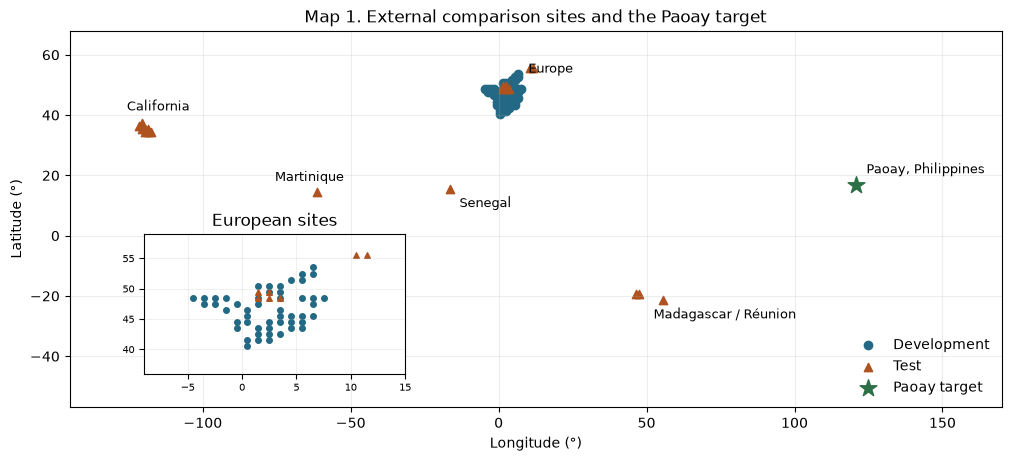

In [4]:
if profile_available:
    locations = parcels[["Split", "Cell"]].drop_duplicates().copy()
    coordinates = locations["Cell"].str.split(",", expand=True).astype(float)
    locations["Latitude"], locations["Longitude"] = coordinates[0] + 0.5, coordinates[1] + 0.5
    locations["Role"] = locations["Split"].replace({"Train": "Development", "Validation": "Development"})
    locations = locations.drop_duplicates(["Role", "Cell"])

    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    europe = ax.inset_axes([0.08, 0.09, 0.28, 0.37])
    for role, marker, color in [("Development", "o", "#236985"), ("Test", "^", "#ae531f")]:
        points = locations[locations["Role"] == role]
        ax.scatter(points["Longitude"], points["Latitude"], label=role, marker=marker, color=color)
        europe.scatter(points["Longitude"], points["Latitude"], marker=marker, color=color, s=16)

    ax.scatter(120.77, 16.64, marker="*", s=160, color="#2d6f46", label="Paoay target")
    for label, lon, lat, offset in [
        ("California", -120, 36, (-12, 12)), ("Europe", 3, 49, (15, 11)),
        ("Senegal", -17, 15, (8, -12)), ("Madagascar / Réunion", 50, -21, (5, -14)),
        ("Martinique", -62, 14, (-29, 9)), ("Paoay, Philippines", 121, 17, (7, 8)),
    ]:
        ax.annotate(label, (lon, lat), xytext=offset, textcoords="offset points", fontsize=9)
    ax.set(xlim=(-145, 170), ylim=(-57, 68), xlabel="Longitude (°)", ylabel="Latitude (°)",
           title="Map 1. External comparison sites and the Paoay target")
    europe.set(xlim=(-9, 15), ylim=(36, 59), title="European sites")
    europe.tick_params(labelsize=7)
    ax.grid(alpha=0.22)
    europe.grid(alpha=0.18)
    ax.legend(loc="lower right", frameon=False)
    plt.show()

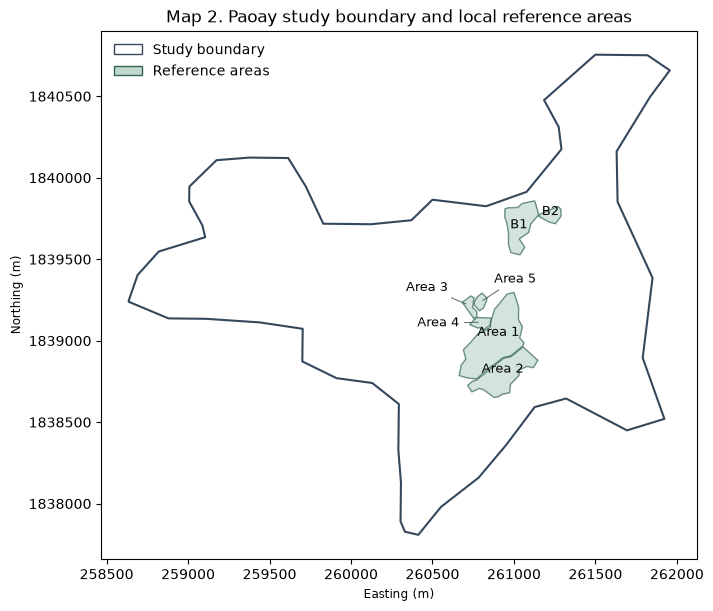

In [5]:
bundle = root / paoay_bundle
if all((bundle / name).is_file() for name in ("roi.geojson", "reference_areas.geojson")):
    boundary = gpd.read_file(bundle / "roi.geojson").to_crs(32651)
    areas = gpd.read_file(bundle / "reference_areas.geojson").to_crs(boundary.crs)
    areas = areas[areas["role"] == "Reference area"]

    fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
    boundary.boundary.plot(ax=ax, color="#35485b", linewidth=1.5, label="Study boundary")
    areas.plot(ax=ax, color="#c0d9cc", edgecolor="#356554", alpha=0.7, label="Reference areas")
    # Place names inside the corresponding polygons.
    label_offsets = {"Area 3": (-30, 10), "Area 4": (-31, -3), "Area 5": (25, 14)}
    for area in areas.itertuples():
        point = area.geometry.representative_point()
        offset = label_offsets.get(area.name, (0, 0))
        leader = {"arrowstyle": "-", "color": "#53665e", "lw": 0.7} if offset != (0, 0) else None
        ax.annotate(area.name, (point.x, point.y), xytext=offset, textcoords="offset points",
                    ha="center", fontsize=9, arrowprops=leader)
    ax.set(title="Map 2. Paoay study boundary and local reference areas",
           xlabel="Easting (m)", ylabel="Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(facecolor="white", edgecolor="#35485b", label="Study boundary"),
        Patch(facecolor="#c0d9cc", edgecolor="#356554", label="Reference areas"),
    ], loc="upper left", frameon=False)
    plt.show()
else:
    print("Paoay map unavailable. Check the saved reference bundle path.")

## 5. How closely labels match the imagery

**Table 4. Reference timing, quality and gaps**

| Evidence | What the saved data establish | What remains uncertain |
|---|---|---|
| European development | The original crop and declaration year are recorded. | The declaration year alone leaves cycle occupancy uncertain. |
| JECAM field observations | Survey dates can be tested against the two imagery windows below. | A date inside the window does not establish occupancy throughout it. |
| California and Denmark supplements | California has a recorded main-crop survey day. Denmark has declarations for the reference year. | The dates leave planting and harvest timing uncertain. |
| Non-JECAM supplements | Original crop wording and label year are retained. | January 1 placeholders are annual evidence. |
| Retired EuroCrops cabbage campaign | Excluded from the active experiment. The team reported insufficient clear-pixel support. | An exact attrition count needs the corresponding quality receipt. |
| Paoay local areas | The saved field review contains zero verified crop observations. | Crop occupancy and local class counts are unknown. |

The date check below uses the recorded observation date and treats the window end as exclusive. Madagascar contributes the strongest highland comparison for carrot and potato. Its small cabbage sample limits the same comparison for cabbage. The Paoay areas shown above help guide fieldwork and imagery assessment.

In [6]:
if profile_available:
    timing = []
    for row in test:
        if row["scope"] != "jecam" or row["cohort"] not in {"fixed_matched", "aligned_matched"}:
            continue
        date = row["raw_matches"][0].get("collection_date") if row["raw_matches"] else None
        day = date[:10] if date else None
        if day == f'{row["source_year"]}-01-01':
            day = None  # A year placeholder cannot establish observation timing.
        timing.append({
            "Window": row["cohort"].split("_")[0].title(), "Crop": row["crop"].title(),
            "Parcel": row["group"], "Dated": int(bool(day)),
            "Inside window": int(bool(day and row["start"] <= day < row["end"])),
        })
    dates = pd.DataFrame(timing).drop_duplicates(["Window", "Parcel"])
    overlap = dates.groupby(["Window", "Crop"]).agg(
        Parcels=("Parcel", "size"), Dated=("Dated", "sum"),
        Inside=("Inside window", "sum"),
    ).reset_index().rename(columns={"Inside": "Inside window"})
    show_table(overlap.to_dict("records"), title="Matched JECAM observation dates and window overlap")

Window,Crop,Parcels,Dated,Inside window
Aligned,Cabbage,11,11,6
Aligned,Carrot,37,37,24
Aligned,Potato,35,35,32
Fixed,Cabbage,11,11,0
Fixed,Carrot,37,37,0
Fixed,Potato,35,35,0


## 6. Collection status and handoff

The saved batch ledger reports selected parcels and collection progress. Use it to identify pending work. The usable counts above come from the completed feature export after imagery and window screening. The next stage is [Preprocessing 01](../preprocessing/01_imagery_quality.ipynb).

In [7]:
collection_manifest = write_summary(root)
summary = json.loads(collection_manifest.read_text())
show_table(summary["profile"], title="Selected parcel groups by source, crop and partition")
batch_status = pd.DataFrame(summary["batches"])
if not batch_status.empty:
    status_counts = batch_status.groupby(["source", "status"]).size().reset_index(name="Batches")
    show_table(status_counts.to_dict("records"), title="Saved collection status by source")
print(f"Metadata issues recorded: {len(summary['issues'])}")
print(f"Collection report: {(collection_manifest.parent / 'report.md').relative_to(root)}")
print(f"Batch manifest: {collection_manifest.relative_to(root)}")

Crop,Partition,Role,Selected parcel groups,Source
Cabbage,Reserved test,external_test,189,cropharvest
Carrot,Reserved test,external_test,520,cropharvest
Potato,Reserved test,external_test,669,cropharvest
Carrot,Reserved test,reserved_development,435,eurocrops
Carrot,Training,development,"1,321",eurocrops
Carrot,Validation,development,438,eurocrops
Cabbage,Reserved test,reserved_development,348,francecrops
Cabbage,Training,development,"1,111",francecrops
Cabbage,Validation,development,341,francecrops
Potato,Reserved test,reserved_development,23,francecrops


Source,Status,Batches
cropharvest,completed,17
cropharvest,skipped,4
eurocrops,completed,22
francecrops,completed,19
sen4agrinet,completed,23
sen4agrinet,skipped,8


Metadata issues recorded: 1
Collection report: pipeline_outputs/collection/reports/summary_458cb75a0a645530/report.md
Batch manifest: pipeline_outputs/collection/reports/summary_458cb75a0a645530/collection_manifest.json
